# Tema VIII - Algoritmos de Aprendizaje No Supervisado: Reglas de Asociación y Clustering

## Objetivos de Aprendizaje

Al finalizar este cuaderno serás capaz de:

- Conocer los fundamentos del Aprendizaje No Supervisado y las Reglas de Asociación
- Utilizar Clustering basados en centroides
- Utilizar Clustering Jerárquicos Aglomerativos y Divisivos
- Utilizar Clustering basados en Densidad
- Realizar Evaluación Diagnóstica de Clustering y selección de K
___

## Fundamentos de Aprendizaje No Supervisado y Reglas de Asociación

### Objetivos

Al finalizar este apartado serás capaz de:

* Formalizar el concepto de aprendizaje no supervisado.
* Entender la estructura de transacciones en el análisis de la cesta de la compra.
* Formular y calcular las métricas esenciales: Soporte, Confianza y Lift.
* Implementar el algoritmo Apriori para descubrir reglas de asociación con _mlxtend_.

### El Aprendizaje No Supervisado y las Reglas de Asociación

En el aprendizaje no supervisado disponemos únicamente de la matriz de características $X$, sin etiquetas $y$. El objetivo es descubrir la estructura subyacente de los datos.

El Análisis de Reglas de Asociación busca relaciones del tipo implícito:

$$\text{Si } A \implies B$$

Donde $A$ (Antecedente) y $B$ (Consecuente) son conjuntos disjuntos de ítems ($A \cap B = \emptyset$).

### Métricas Fundamentales de Asociación

Dada una base de datos de transacciones $N$:

1. Soporte (Support)Mide la frecuencia absoluta o relativa con la que un conjunto de ítems aparece en el total de transacciones:

$$\text{Soporte}(A \implies B) = P(A \cup B) = \frac{\text{Nº de transacciones que contienen } A \text{ y } B}{N}$$

2. Confianza (Confidence)

Mide la probabilidad condicional de encontrar el ítem $B$ en una transacción sabiendo que esta ya contiene el ítem $A$:

$$\text{Confianza}(A \implies B) = P(B \vert{} A) = \frac{\text{Soporte}(A \cup B)}{\text{Soporte}(A)}$$

3. Lift (Elevación)

Mide la fuerza de la regla respecto a la independencia estadística entre $A$ y $B$:

$$\text{Lift}(A \implies B) = \frac{P(A \cup B)}{P(A) \times P(B)} = \frac{\text{Confianza}(A \implies B)}{\text{Soporte}(B)}$$

$\text{Lift} = 1$: $A$ y $B$ son independientes. La regla no aporta información.

$\text{Lift} > 1$: Asociación positiva. La presencia de $A$ incrementa la probabilidad de que ocurra $B$.

$\text{Lift} < 1$: Asociación negativa (efecto sustitución/repulsión).

Para trabajar con reglas de asociación, se convierte la matriz de transacciones en un formato binario (One-Hot Encoded) y se aplica el algoritmo Apriori.

In [50]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from kmedoids import KMedoids
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [51]:
# 1. Ejemplo de base de datos transaccional
transacciones = [
    ["Leche", "Pan", "Pañales"],
    ["Leche", "Cerveza", "Pañales", "Huevos"],
    ["Leche", "Pan", "Cerveza", "Pañales"],
    ["Pan", "Leche", "Huevos"],
    ["Cerveza", "Pañales"]
]

# 2. Transformación a matriz booleana (One-Hot)
te = TransactionEncoder()
te_ary = te.fit(transacciones).transform(transacciones)
df_trans = pd.DataFrame(te_ary, columns=te.columns_)

# 3. Extracción de itemsets frecuentes con un Soporte Mínimo del 40%
itemsets_frecuentes = apriori(df_trans, min_support=0.4, use_colnames=True)

# 4. Generación de reglas filtrando por Confianza o Lift
reglas = association_rules(itemsets_frecuentes, metric="lift", min_threshold=1.0)

# 5. Visualización de las reglas ordenadas por Lift
print(reglas[["antecedents", "consequents", "support", "confidence", "lift"]].sort_values(by="lift", ascending=False))

                    antecedents                  consequents  support  \
0          frozenset({Cerveza})         frozenset({Pañales})      0.6   
2           frozenset({Huevos})           frozenset({Leche})      0.4   
4              frozenset({Pan})           frozenset({Leche})      0.6   
3            frozenset({Leche})          frozenset({Huevos})      0.4   
9          frozenset({Pañales})  frozenset({Leche, Cerveza})      0.4   
6   frozenset({Leche, Cerveza})         frozenset({Pañales})      0.4   
13           frozenset({Leche})    frozenset({Pan, Pañales})      0.4   
10    frozenset({Pan, Pañales})           frozenset({Leche})      0.4   
5            frozenset({Leche})             frozenset({Pan})      0.6   
1          frozenset({Pañales})         frozenset({Cerveza})      0.6   
8          frozenset({Cerveza})  frozenset({Leche, Pañales})      0.4   
7   frozenset({Leche, Pañales})         frozenset({Cerveza})      0.4   
11  frozenset({Leche, Pañales})             frozens

### Ideas Clave

- No requiere target: A diferencia de los temas anteriores, las reglas de asociación no predicen una variable $y$; buscan patrones de coocurrencia en listas de eventos/compras.
- Interpretación del Lift: Un valor alto de Confianza puede ser engañoso si el consecuente $B$ es un producto extremadamente popular por sí solo. El Lift corrige este sesgo al comparar con la frecuencia base de $B$.
- Formato de datos: Es necesario transformar listas de transacciones heterogéneas mediante TransactionEncoder o pd.get_dummies antes de procesar con apriori.
___

## Clustering Basado en Centroides ($K$-Means y $K$-Medoids)

### Objetivos

Al finalizar este apartado serás capaz de:

* Comprender la formulación matemática del algoritmo $K$-Means y el concepto de Inercia (WCSS).
* Analizar el algoritmo de inicialización $K$-Means++ para mitigar la convergencia a mínimos locales subóptimos.
* Evaluar la extrema sensibilidad de los métodos basados en centroides al escalado de características.
* Estudiar el algoritmo PAM / $K$-Medoids como alternativa robusta frente a valores atípicos (outliers).

### Algoritmo $K$-Means

$K$-Means particiona un conjunto de $n$ observaciones en $K$ clústeres disjuntos $S = \{S_1, S_2, \dots, S_K\}$, asignando cada punto al centroide $\boldsymbol{\mu}_k$ más cercano en términos de distancia euclídea.

**Formulación Matemática (Minimización de la Inercia)**

El objetivo es encontrar la asignación de clústeres y centroides que minimice la Suma de Cuadrados Intra-Clúster (Within-Cluster Sum of Squares o WCSS), también conocida simplemente como Inercia:

$$\arg\min_{S} \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in S_k} \Vert{}\mathbf{x}_i - \boldsymbol{\mu}_k\Vert{}^2_2$$

Donde $\boldsymbol{\mu}_k = \frac{1}{\vert{}S_k\vert{}} \sum_{\mathbf{x}_i \in S_k} \mathbf{x}_i$ representa el centroide (media aritmética) del clúster $k$.

**Algoritmo de Lloyd (Proceso Iterativo)**

1. Inicialización: Seleccionar $K$ centroides iniciales $\{\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_K\}$.
2. Paso de Asignación: Asignar cada observación $\mathbf{x}_i$ al clúster cuyo centroide esté a menor distancia euclídea.
3. Paso de Actualización: Recalcular la posición de cada centroide $\boldsymbol{\mu}_k$ como la media aritmética de todos los puntos asignados a $S_k$.
4. Convergencia: Repetir los pasos 2 y 3 hasta que la posición de los centroides no cambie o se alcance el número máximo de iteraciones.

### Inicialización Inteligente: $K$-Means++

La inicialización aleatoria tradicional de centroides puede provocar que el algoritmo converja a mínimos locales deficientes. $K$-Means++ resuelve este problema seleccionando centroides iniciales distribuidos de forma probabilística:

1. El primer centroide $\boldsymbol{\mu}_1$ se elige aleatoriamente de entre los puntos de datos.
2. Para cada punto $\mathbf{x}_i$, se calcula la distancia mínima $D(\mathbf{x}_i)$ al centroide más cercano ya seleccionado.
3. El siguiente centroide se elige con una probabilidad proporcional a $D(\mathbf{x}_i)^2$.
4. Se repiten los pasos 2 y 3 hasta seleccionar los $K$ centroides iniciales.

### $K$-Medoids (PAM - Partitioning Around Medoids)

En $K$-Means, el centroide es la media aritmética de los puntos del clúster, lo que hace que un solo valor atípico (outlier) lejano desplace significativamente la posición del centroide.

$K$-Medoids mitiga este problema restrictivo:

- Representante real: Utiliza un punto real del conjunto de datos (medoide) como centro de cada clúster, en lugar de una media artificial.
- Métricas flexibles: Permite optimizar distancias no euclídeas (Manhattan, Coseno) reduciendo la sensibilidad a ruido y outliers.

In [52]:
df = pd.read_excel("RENDIMIENTO.xlsx")

X = df.drop(columns=['NF'])

# 1. Definición del Pipeline con K-Means++
pipeline_kmeans = Pipeline([
    ("scaler", StandardScaler()),
    ("clustering", KMeans(
        n_clusters=4,
        init="k-means++",  # Inicialización óptima por defecto
        n_init=10,         # Número de ejecuciones independientes con diferentes semillas
        max_iter=300,
        random_state=42
    ))
])

# 2. Ajuste e inferencia de etiquetas
# En aprendizaje no supervisado fit_predict realiza ambos pasos sobre X
etiquetas_clusters = pipeline_kmeans.fit_predict(X)

print(etiquetas_clusters)

# 3. Extracción de centroides e inercia del modelo
kmeans_model = pipeline_kmeans.named_steps["clustering"]
centroides_escalados = kmeans_model.cluster_centers_
inercia_wcss = kmeans_model.inertia_

print(f"Inercia (WCSS): {inercia_wcss:.2f}")

[1 1 3 1 1 1 1 1 3 1 1 1 1 1 3 1 1 3 0 1 1 1 1 3 1 3 3 1 1 3 1 1 1 3 1 1 1
 1 1 3 1 1 3 1 1 1 0 1 1 1 1 3 1 1 3 1 1 3 3 1 3 1 1 1 1 1 3 1 1 1 3 1 1 1
 1 1 1 3 1 3 1 0 1 3 1 3 3 1 3 3 1 0 1 3 3 3 3 3 1 3 1 1 3 1 3 1 1 1 3 1 3
 3 1 3 3 3 3 1 3 1 3 0 3 1 3 1 1 1 1 3 3 1 1 3 1 3 3 3 1 3 1 1 3 3 3 3 1 1
 3 1 1 1 3 1 3 1 3 3 3 3 3 1 0 1 3 1 3 3 3 1 3 3 3 1 3 3 3 3 0 3 3 3 1 3 3
 3 1 3 1 3 1 3 3 1 3 1 1 3 3 1 1 3 3 3 0 3 3 1 0 1 1 3 0 1 3 1 1 1 0 1 3 3
 1 3 1 3 3 3 1 1 1 3 3 1 1 3 1 1 0 3 1 1 3 3 0 1 1 1 1 1 3 1 3 1 1 1 3 3 1
 1 1 1 1 1 3 3 3 3 1 0 1 1 1 3 1 1 1 3 1 1 1 0 1 1 1 3 3 3 1 1 3 1 1 3 3 3
 3 3 1 1 1 1 1 3 3 1 3 3 1 3 1 1 0 1 3 1 1 1 3 3 1 3 1 3 3 3 3 3 3 3 3 3 1
 1 1 1 3 3 1 1 0 3 1 1 3 0 1 3 1 3 3 3 3 1 1 1 1 1 1 3 3 1 1 0 1 3 3 3 3 3
 1 3 3 1 3 1 3 3 3 3 3 3 3 1 1 1 1 3 1 3 3 3 3 1 0 3 3 3 3 1 0 3 3 3 3 3 3
 0 3 1 3 3 3 1 0 3 1 1 1 1 3 1 1 3 1 1 1 3 3 1 0 3 3 3 3 3 3 3 1 3 3 1 3 3
 3 3 3 1 1 1 1 1 1 1 1 1 1 1 3 1 1 3 1 1 1 1 1 1 1 1 3 1 3 1 1 3 3 1 1 3 3
 1 1 1 1 3 1 1 1 1 1 1 3 

**Alternativa con $K$-Medoids (scikit-learn-extra)**

In [53]:
# Pipeline con K-Medoids usando distancia Manhattan (robusto a outliers)
pipeline_kmedoids = Pipeline([
    ("scaler", StandardScaler()),
    ("clustering", KMedoids(
        n_clusters=4,
        metric="manhattan",
        method="pam",
        random_state=42
    ))
])

etiquetas_medoids = pipeline_kmedoids.fit_predict(X)
print(etiquetas_medoids)

# Extracción de centroides e inercia del modelo
kmedoids_model = pipeline_kmedoids.named_steps["clustering"]
centroides_escalados = kmedoids_model.cluster_centers_
inercia_wcss = kmedoids_model.inertia_

print(f"Inercia (WCSS): {inercia_wcss:.2f}")

[3 2 3 1 1 0 2 0 3 3 1 2 2 0 3 0 1 3 1 1 1 1 2 3 2 3 3 1 1 3 3 1 0 3 2 0 1
 1 1 3 0 0 3 3 0 0 0 1 1 2 3 3 1 0 3 1 0 3 3 2 3 0 1 3 0 1 3 1 1 2 3 0 1 0
 1 1 2 3 1 3 1 0 0 3 1 3 3 2 1 1 2 0 0 3 1 3 3 3 1 3 2 0 3 1 1 0 1 1 3 2 3
 3 1 3 1 3 3 0 3 1 1 1 3 1 3 0 0 0 1 1 3 1 1 1 0 3 3 1 1 3 2 1 3 3 3 3 0 1
 3 1 1 1 3 3 3 0 3 3 3 3 3 0 0 0 3 0 3 3 3 3 3 3 3 0 3 3 3 3 0 3 3 3 0 3 3
 3 0 3 0 3 0 3 3 0 3 0 0 3 3 3 0 3 3 3 0 3 3 3 0 3 0 3 0 0 3 0 0 0 0 3 3 3
 0 3 0 3 3 3 0 0 0 3 3 1 1 3 2 1 0 1 1 1 3 1 0 1 0 1 1 2 3 0 1 1 0 1 3 3 1
 2 1 1 1 0 1 3 3 3 1 0 0 2 1 3 1 1 1 3 2 2 2 0 1 1 1 1 3 1 2 1 3 2 2 3 1 3
 3 3 2 2 2 1 2 3 3 1 3 3 1 1 0 1 0 1 1 0 0 1 3 3 1 3 1 3 3 3 3 3 3 3 3 3 0
 1 1 1 1 3 0 0 0 3 1 0 3 0 0 3 0 3 3 3 3 0 0 0 1 0 0 3 3 1 3 0 0 3 3 3 3 3
 1 3 3 3 3 1 3 3 3 3 3 3 3 1 3 0 1 3 0 3 3 3 3 1 3 3 3 3 3 0 0 3 3 3 3 3 3
 0 3 0 3 3 3 1 0 3 0 0 1 0 3 1 0 1 1 1 3 3 3 1 0 3 3 3 3 1 3 3 1 1 3 3 3 3
 3 3 3 1 1 2 0 0 0 0 0 2 1 1 1 0 0 1 0 1 0 2 1 0 1 1 1 0 3 1 0 1 1 0 1 1 3
 1 1 1 1 1 2 2 1 2 1 2 3 

**Cuadro Comparativo de Algoritmos de Centroides**

|Criterio|K-Means|K-Medoids (PAM)|
|--------|-------|---------------|
|Centro del Clúster|Media virtual (Punto hipotético μk​)|Medoide real (Observación existente en X)|
|Métrica por Defecto|Distancia Euclídea|Cualquier métrica de distancia (Euclídea, Manhattan)|
|Sensibilidad a Outliers|Alta (La media se desplaza fácilmente)|Baja (Métrica mediana/medoide más estable)|
|Complejidad Computacional|$O(n⋅K⋅d⋅iter)$ — Muy Rápido|$O(K⋅(n−K)2)$ — Más lento en conjuntos grandes|
|Geometría de Clústeres|Asume clústeres esféricos e igual varianza|Soporta formas convexas pero limitadas por distancias|

### Ideas Clave

- Estandarización obligatoria: $K$-Means basa la asignación en la distancia euclídea $\Vert{}\mathbf{x}_i - \boldsymbol{\mu}_k\Vert{}_2$. Si una variable tiene un rango en miles y otra en decimales, la primera dominará por completo el cálculo de distancias si no se aplica StandardScaler.
- Efecto de la inercia: La inercia (WCSS) siempre disminuye monótonamente al aumentar el número de clústeres $K$, alcanzando $0$ cuando $K = n$. Por tanto, no se debe usar la inercia de forma aislada para elegir $K$ sin aplicar métodos como el del Codo o el de la Silueta.
- Asunción de esfericidad: $K$-Means asume implícitamente que los clústeres son convexos, esféricos y de densidad similar. Falla en estructuras no esféricas (ej. anillos concéntricos o formas de semiluna).
___

## Clustering Jerárquico Aglomerativo y Dendrogramas

### Objetivos

Al finalizar este apartado serás capaz de:

* Comprender la estrategia ascendente (bottom-up) del algoritmo de Clustering Jerárquico Aglomerativo.
* Estudiar los diferentes criterios de enlace (Linkage Criteria): Ward, Complete, Average y Single.
* Construir e interpretar visualmente un Dendrograma para determinar el número óptimo de cortes/clústeres.
* Implementar AgglomerativeClustering de Scikit-Learn e integrarlo con SciPy para análisis jerárquico.

### Clustering Jerárquico Aglomerativo

El agrupamiento jerárquico aglomerativo construye una jerarquía de clústeres de forma ascendente:

1. Inicialización: Cada observación empieza en su propio clúster individual ($n$ clústeres iniciales).
2. Matriz de Distancias: Se calcula la matriz de disimilitud entre todos los pares de clústeres.
3. Fusión: Se identifican y fusionan los dos clústeres más cercanos según un criterio de enlace determinado.
4. Iteración: Se recalcula la matriz de distancias y se repite el proceso hasta que todas las observaciones queden agrupadas en un único clúster global.

### Criterios de Enlace (Linkage Criteria)

El criterio de enlace define matemáticamente cómo se mide la distancia entre dos conjuntos de puntos $A$ y $B$:

1. Enlace de Ward (linkage='ward')

Minimiza el incremento de la varianza total dentro de los clústeres (Within-Cluster Variance) al fusionar $A$ y $B$. Es el criterio por defecto y suele generar clústeres homogéneos y de tamaños equilibrados.

$$\Delta \text{Var} = \frac{\vert{}A\vert{} \cdot \vert{}B\vert{}}{\vert{}A\vert{} + \vert{}B\vert{}} \Vert{}\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\Vert{}^2_2$$

2. Enlace Completo / Máximo (linkage='complete')

Mide la distancia entre los dos puntos más lejanos pertenecientes a cada clúster:

$$D(A, B) = \max \{ d(\mathbf{x}_a, \mathbf{x}_b) : \mathbf{x}_a \in A, \mathbf{x}_b \in B \}$$

Tiende a romper grupos grandes y genera clústeres compactos de diámetros similares.

3. Enlace Promedio (linkage='average')

Mide la distancia media entre todos los pares posibles de observaciones:

$$D(A, B) = \frac{1}{\vert{}A\vert{} \cdot \vert{}B\vert{}} \sum_{\mathbf{x}_a \in A} \sum_{\mathbf{x}_b \in B} d(\mathbf{x}_a, \mathbf{x}_b)$$

4. Enlace Simple / Mínimo (linkage='single')

Mide la distancia entre los dos puntos más cercanos:

$$D(A, B) = \min \{ d(\mathbf{x}_a, \mathbf{x}_b) : \mathbf{x}_a \in A, \mathbf{x}_b \in B \}$$

Sufre del fenómeno de encadenamiento (chaining effect), fusionando clústeres a través de cadenas de puntos intermedios, pero es útil para formas no esféricas.

### Construcción e Interpretación de Dendrogramas

El Dendrograma es un diagrama en forma de árbol que ilustra el orden y las distancias a las que se van fusionando los clústeres:

- Eje Vertical (Distancia/Altura): Representa la disimilitud a la que dos clústeres se unen. Un salto vertical largo indica una clara separación natural entre grupos.
- Corte Horizontal: Al trazar una línea horizontal a una determinada altura del dendrograma, se determina el número final de clústeres $K$.

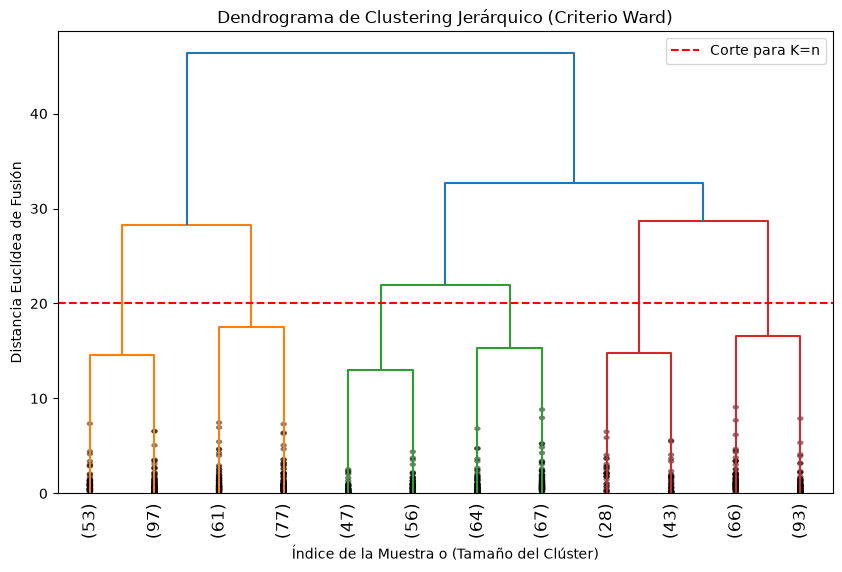

[2 3 2 4 4 5 3 3 1 2 4 3 3 5 1 5 4 2 4 4 4 4 3 1 3 1 1 2 4 2 2 4 5 2 3 4 3
 3 4 1 5 3 2 2 3 4 5 4 4 3 2 2 3 3 1 3 2 2 1 2 2 3 2 2 3 3 1 4 4 3 4 3 2 2
 4 4 3 1 4 1 4 5 3 1 4 1 1 3 4 2 3 5 5 1 4 1 1 1 4 1 3 5 1 4 2 5 4 4 2 3 4
 1 4 2 2 1 1 4 2 4 2 4 1 2 1 2 3 5 4 4 1 4 4 4 5 2 1 4 4 1 2 4 1 1 1 2 5 4
 1 4 4 4 1 2 4 3 1 2 2 2 1 4 5 4 1 5 1 1 1 2 1 1 1 4 1 2 1 1 4 1 1 1 3 1 1
 2 3 1 3 2 4 1 4 2 1 5 2 1 1 2 5 4 2 1 5 1 1 2 5 4 5 4 5 5 1 5 3 5 5 2 2 2
 5 1 4 2 1 2 4 5 5 1 1 2 4 1 2 2 5 1 3 4 1 2 5 4 3 4 4 3 1 5 4 4 5 4 1 1 4
 3 4 2 4 4 4 1 1 2 2 4 2 3 4 1 3 3 4 1 3 3 2 5 4 4 4 1 1 1 3 2 1 3 2 1 1 1
 1 1 3 3 3 4 3 1 1 3 2 1 3 4 5 3 5 4 4 3 3 3 1 1 3 1 4 2 1 1 1 1 2 1 1 1 3
 4 3 3 4 1 2 4 5 1 3 3 1 5 5 1 4 4 1 1 1 5 5 3 4 3 2 1 1 3 2 5 3 1 2 1 2 1
 3 1 1 2 1 3 1 1 1 1 1 1 1 4 4 5 4 4 4 1 1 1 1 3 5 1 1 1 1 4 5 1 1 1 4 1 1
 5 1 4 1 1 1 4 5 1 4 3 4 5 1 3 3 4 3 3 2 1 1 3 5 1 1 1 1 4 4 1 4 4 1 2 1 1
 1 2 1 4 4 3 3 3 3 3 3 3 3 3 4 3 3 4 3 3 3 3 3 3 3 3 4 3 1 4 3 4 4 3 4 4 4
 4 4 4 4 1 2 2 4 3 4 3 4 

In [54]:
# 1. Es obligatorio escalar los datos antes de calcular distancias
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Generación de la matriz de enlace (Linkage Matrix) usando SciPy
matriz_enlace = linkage(X_scaled, method="ward", metric="euclidean")

# 3. Representación del Dendrograma
corte = 20.0
plt.figure(figsize=(10, 6))
dendrogram(
    matriz_enlace,
    truncate_mode="lastp",  # Simplifica la visualización mostrando solo los últimos 'p' clústeres
    p=12,
    leaf_rotation=90.0,
    leaf_font_size=12.0,
    show_contracted=True
)
plt.title("Dendrograma de Clustering Jerárquico (Criterio Ward)")
plt.xlabel("Índice de la Muestra o (Tamaño del Clúster)")
plt.ylabel("Distancia Euclídea de Fusión")
plt.axhline(y=corte, color="r", linestyle="--", label="Corte para K=n")
plt.legend()
plt.show()

# 4. Extraer el clúster (1, 2 o 3) para cada fila de tus datos originales
etiquetas_cluster = fcluster(matriz_enlace, t=corte, criterion="distance")
print(etiquetas_cluster)

### Alternativa utilizando AgglomerativeClustering

Una vez identificado el número de clústeres en el dendrograma (o fijado por requisitos de negocio), se utiliza AgglomerativeClustering:

In [55]:
# Pipeline con AgglomerativeClustering
pipeline_jerarquico = Pipeline([
    ("scaler", StandardScaler()),
    ("clustering", AgglomerativeClustering(
        n_clusters=6,
        metric="euclidean",  # O 'manhattan', 'cosine' (solo si linkage != 'ward')
        linkage="ward"
    ))
])

# Obtención de etiquetas
etiquetas_jerarquicas = pipeline_jerarquico.fit_predict(X)
print(etiquetas_jerarquicas)

[0 5 0 2 2 3 5 5 4 0 2 5 5 3 4 3 2 0 2 2 2 2 5 4 5 4 4 0 2 0 0 2 3 0 5 2 5
 5 2 4 3 5 0 0 5 2 3 2 2 5 0 0 5 5 4 5 0 0 4 0 0 5 0 0 5 5 4 2 2 5 2 5 0 0
 2 2 5 4 2 4 2 3 5 4 2 4 4 5 2 0 5 3 3 4 2 4 4 4 2 4 5 3 4 2 0 3 2 2 0 5 2
 4 2 0 0 4 4 2 0 2 0 2 4 0 4 0 5 3 2 2 4 2 2 2 3 0 4 2 2 4 0 2 4 4 4 0 3 2
 4 2 2 2 4 0 2 5 4 0 0 0 4 2 3 2 4 3 4 4 4 0 4 4 4 2 4 0 4 4 2 4 4 4 5 4 4
 0 5 4 5 0 2 4 2 0 4 3 0 4 4 0 3 2 0 4 3 4 4 0 3 2 3 2 3 3 4 3 5 3 3 0 0 0
 3 4 2 0 4 0 2 3 3 4 4 0 2 4 0 0 3 4 5 2 4 0 3 2 5 2 2 5 4 3 2 2 3 2 4 4 2
 5 2 0 2 2 2 4 4 0 0 2 0 5 2 4 5 5 2 4 5 5 0 3 2 2 2 4 4 4 5 0 4 5 0 4 4 4
 4 4 5 5 5 2 5 4 4 5 0 4 5 2 3 5 3 2 2 5 5 5 4 4 5 4 2 0 4 4 4 4 0 4 4 4 5
 2 5 5 2 4 0 2 3 4 5 5 4 3 3 4 2 2 4 4 4 3 3 5 2 5 0 4 4 5 0 3 5 4 0 4 0 4
 5 4 4 0 4 5 4 4 4 4 4 4 4 2 2 3 2 2 2 4 4 4 4 5 3 4 4 4 4 2 3 4 4 4 2 4 4
 3 4 2 4 4 4 2 3 4 2 5 2 3 4 5 5 2 5 5 0 4 4 5 3 4 4 4 4 2 2 4 2 2 4 0 4 4
 4 0 4 2 2 5 5 5 5 5 5 5 5 5 2 5 5 2 5 5 5 5 5 5 5 5 2 5 4 2 5 2 2 5 2 2 2
 2 2 2 2 4 0 0 2 5 2 5 2 

### Ideas Clave

- No requiere prefijar $K$ de antemano: A diferencia de $K$-Means, el clustering jerárquico genera toda la estructura de árbol en una sola ejecución. La elección del número de clústeres $K$ se realiza a posteriori analizando el dendrograma.
- Restricción del criterio Ward: El método de enlace ward requiere matemáticamente trabajar con la distancia euclídea (metric='euclidean'). Si se utilizan métricas como manhattan o cosine, se debe seleccionar otro enlace (complete, average o single).
- Costo computacional y memoria: La matriz de distancias requiere una memoria de $\mathcal{O}(n^2)$ y un tiempo de ejecución de $\mathcal{O}(n^3)$ (reductible a $\mathcal{O}(n^2 \log n)$). Por este motivo, el clustering jerárquico puro no se recomienda para conjuntos de datos masivos ($n > 20.000$).
___

## Clustering Basado en Densidad (DBSCAN)

### Objetivos

Al finalizar este apartado serás capaz de:

* Comprender la lógica del algoritmo DBSCAN (Density-Based Spatial Clustering of Applications with Noise).
* Clasificar las observaciones según la densidad de su vecindario en Puntos Núcleo (Core), Puntos Frontera (Border) y Ruido (Noise).
* Analizar la capacidad de DBSCAN para detectar clústeres con formas geométricas arbitrarias/no esféricas.
* Determinar la selección heurística de sus dos hiperparámetros fundamentales: $\epsilon$ (eps) y min_samples.

### Principios Teóricos de DBSCAN

A diferencia de $K$-Means o el Clustering Jerárquico, DBSCAN define los clústeres como regiones continuas de alta densidad separadas por regiones de baja densidad.

**Conceptos Fundamentales de Densidad**

Dada una distancia $\epsilon > 0$ y un número mínimo de puntos min_samples ($m$):

1. $\epsilon$-Vecindario ($N_\epsilon(\mathbf{x})$): Conjunto de observaciones situadas a una distancia menor o igual a $\epsilon$ del punto $\mathbf{x}$.

2. Punto Núcleo (Core Point): Una observación $\mathbf{x}$ cuyo $\epsilon$-vecindario contiene al menos $m$ puntos (incluyéndose a sí mismo):

$$\vert{}N_\epsilon(\mathbf{x})\vert{} \ge m$$

3. Punto Frontera (Border Point): Un punto que no cumple la condición de punto núcleo, pero pertenece al $\epsilon$-vecindario de algún punto núcleo.

4. Ruido (Noise Point / Outlier): Cualquier punto que no es ni núcleo ni frontera.

**Alcance y Conectividad por Densidad**

- Alcanzabilidad Directa por Densidad: Un punto $\mathbf{y}$ es directamente alcanzable desde $\mathbf{x}$ si $\mathbf{x}$ es un Punto Núcleo y $\mathbf{y} \in N_\epsilon(\mathbf{x})$.

- Conectividad por Densidad: Dos puntos $\mathbf{p}$ y $\mathbf{q}$ están conectados por densidad si existe una cadena de puntos núcleos que une a ambos. Un clúster en DBSCAN es el conjunto maximal de puntos conectados por densidad.

### Ventajas y Limitaciones de DBSCAN

**Ventajas**

- No requiere prefijar $K$: El número de clústeres surge de forma dinámica a partir de la densidad de los datos.
- Geometría arbitraria: Detecta agrupaciones de cualquier forma (anillos, serpentinas, estructuras concéntricas).
- Detección explícita de outliers: Asigna la etiqueta -1 al ruido o anomalías de forma nativa.

**Limitaciones**

- Densidades variables: Si los datos contienen clústeres con densidades sensiblemente distintas, una única combinación de $\epsilon$ y min_samples no podrá capturarlos a todos (para este caso se utiliza HDBSCAN).
- Sensibilidad al escalado: Depende críticamente de la métrica de distancia elegida.

### Heurística para la Selección de Hiperparámetros

1. min_samples ($m$): Como regla empírica general para datos continuos:

$$m \ge p + 1 \quad \text{o preferiblemente } m = 2 \cdot p$$

donde $p$ es el número de características/dimensiones de la matriz $X$.

2. $\epsilon$ (eps): Se determina analizando el gráfico de las $k$-distancias ($k = m - 1$):

- Se calcula la distancia de cada punto a su $k$-ésimo vecino más cercano.
- Se ordenan las distancias de menor a mayor y se grafican.
- El valor óptimo de $\epsilon$ se sitúa en el punto de inflexión ("codo") de la curva.

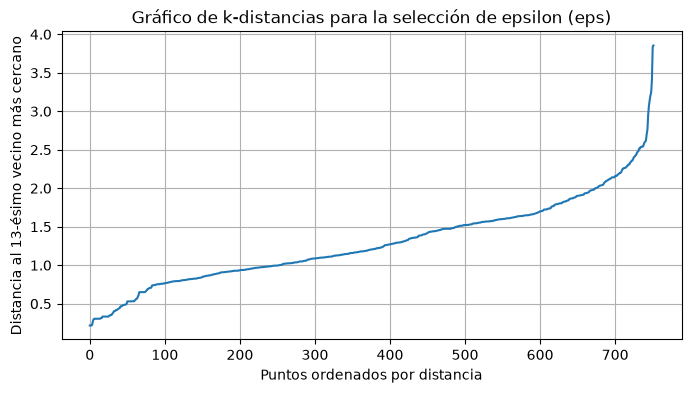

In [56]:
# 1. Escalado obligatorio de los datos
X_scaled = StandardScaler().fit_transform(X)

# 2. Determinación de min_samples (ej. m = 2 * p)
p = X_scaled.shape[1]
min_samples = 2 * p
k = min_samples - 1

# 3. Cálculo de las k-distancias
vecinos = NearestNeighbors(n_neighbors=k)
vecinos.fit(X_scaled)
distancias, _ = vecinos.kneighbors(X_scaled)

# Ordenar las distancias del k-ésimo vecino
distancias_k = np.sort(distancias[:, -1])

# 4. Gráfico del "Codo" para seleccionar epsilon (eps)
plt.figure(figsize=(8, 4))
plt.plot(distancias_k)
plt.ylabel(f"Distancia al {k}-ésimo vecino más cercano")
plt.xlabel("Puntos ordenados por distancia")
plt.title("Gráfico de k-distancias para la selección de epsilon (eps)")
plt.grid(True)
plt.show()

**Implementación con DBSCAN**

In [57]:
# Pipeline completo con DBSCAN
pipeline_dbscan = Pipeline([
    ("scaler", StandardScaler()),
    ("clustering", DBSCAN(
        eps=1.8,              # Valor de la distancia epsilon hallado en la curva k-distancia
        min_samples=13,         # Número mínimo de puntos en el vecindario
        metric="euclidean"     # O 'manhattan', 'cosine'
    ))
])

# Obtención de etiquetas (Ruido = -1)
etiquetas_dbscan = pipeline_dbscan.fit_predict(X)
print(etiquetas_dbscan)

# Inspección de los clústeres y del ruido detectado
n_clusters = len(set(etiquetas_dbscan)) - (1 if -1 in etiquetas_dbscan else 0)
n_ruido = list(etiquetas_dbscan).count(-1)

print(f"Número de clústeres estimados: {n_clusters}")
print(f"Número de observaciones clasificadas como ruido (outliers): {n_ruido}")

[ 1  0  1  0  0  0  0  0  1  1  0  0  0  0  1  0  0  1  0  0  0  0  0  1
  0  1  1  1  0  1  1  0  1  1  0  0  0  0  0  1  0  0  1  1  0  0  0  0
  0  0  1  1  0  0  1  0  1  1  1  1  1  0  1  1  0  0  1 -1  0  0  0  0
  1  1  0  0  0  1  0  1  0  0  0  1  0  1  1  0  0  1  0  0  0  1  0  1
  1  1  0  1  0  0  1  0  1  0  0  0  1  0  0  1  0  1  1  1  1  0  1  0
  1  0  1  1  1  1  0  0  0  0  1  0  0  0  0  1  1  0  0  1  1  0  1  1
  1  1  0  0  1  0  0  0  1  1  0  0  1  1  1  1  1  0  0  0  1  0  1  1
  1  1  1  1  1  0  1  1  1  1 -1  1  1  1  0  1  1  1  0  1  0  1  0  1
  0  1  1  0  1  1  1  1  0  0  1  1  0  1  1  1  0  0  0  0 -1  0  1  0
  0  0 -1  1  1  1  0  1  0  1  1  1  0  0  0  1  1  1  0  1  1  1 -1  1
  0  0  1  1 -1  0  0  0  0  0  1  1  0  0  0  0  1  1  0  0  0  1  0  0
  0  1  1  1  1 -1  1  0  0  1  0  0  0  1  0  0  1 -1  0  0  0  1  1  1
  0  1  1  0  1  1  1  1  1  1  0  0  0  0  0  1  1  0  1  1  0  0  0  0
  0  0  0  0  0  0  1  1  0  1  0  1  1  1  1  1  1

**Alternativa con HDBSCAN**

In [58]:
# Pipeline completo con HDBSCAN
pipeline_hdbscan = Pipeline([
    ("scaler", StandardScaler()),
    ("clustering", HDBSCAN(
        min_cluster_size=15,         # Tamaño mínimo del cluster
    ))
])

# Obtención de etiquetas (Ruido = -1)
etiquetas_hdbscan = pipeline_hdbscan.fit_predict(X)
print(etiquetas_dbscan)

# Inspección de los clústeres y del ruido detectado
n_clusters = len(set(etiquetas_hdbscan)) - (1 if -1 in etiquetas_dbscan else 0)
n_ruido = list(etiquetas_hdbscan).count(-1)

print(f"Número de clústeres estimados: {n_clusters}")
print(f"Número de observaciones clasificadas como ruido (outliers): {n_ruido}")

[ 1  0  1  0  0  0  0  0  1  1  0  0  0  0  1  0  0  1  0  0  0  0  0  1
  0  1  1  1  0  1  1  0  1  1  0  0  0  0  0  1  0  0  1  1  0  0  0  0
  0  0  1  1  0  0  1  0  1  1  1  1  1  0  1  1  0  0  1 -1  0  0  0  0
  1  1  0  0  0  1  0  1  0  0  0  1  0  1  1  0  0  1  0  0  0  1  0  1
  1  1  0  1  0  0  1  0  1  0  0  0  1  0  0  1  0  1  1  1  1  0  1  0
  1  0  1  1  1  1  0  0  0  0  1  0  0  0  0  1  1  0  0  1  1  0  1  1
  1  1  0  0  1  0  0  0  1  1  0  0  1  1  1  1  1  0  0  0  1  0  1  1
  1  1  1  1  1  0  1  1  1  1 -1  1  1  1  0  1  1  1  0  1  0  1  0  1
  0  1  1  0  1  1  1  1  0  0  1  1  0  1  1  1  0  0  0  0 -1  0  1  0
  0  0 -1  1  1  1  0  1  0  1  1  1  0  0  0  1  1  1  0  1  1  1 -1  1
  0  0  1  1 -1  0  0  0  0  0  1  1  0  0  0  0  1  1  0  0  0  1  0  0
  0  1  1  1  1 -1  1  0  0  1  0  0  0  1  0  0  1 -1  0  0  0  1  1  1
  0  1  1  0  1  1  1  1  1  1  0  0  0  0  0  1  1  0  1  1  0  0  0  0
  0  0  0  0  0  0  1  1  0  1  0  1  1  1  1  1  1

c:\Users\jorge.crespo.UNEATPDIPAS\Documents\TÉCNICAS DE PROGRAMACIÓN EN IA\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


**Cuadro Comparativo**

|Criterio|K-Means|Clustering Jerárquico|DBSCAN y HDBSCAN|
|--------|-------|---------------------|----------------|
|Enfoque|Basado en Centroides|Jerarquía Ascendente/Descendente|Basado en Densidad|
|Requiere definir K|Sí (De antemano)|No (Se corta el dendrograma)|No (Surge dinámicamente)|
|Formas de Clúster|Únicamente esféricas/convexas|Diversas (según el linkage)|Arbitrarias y no esféricas|
|Tratamiento del Ruido|Asigna todos los puntos a un clúster|Asigna todos los puntos a un clúster|Detecta ruido explícitamente (-1)|
|Parámetros Clave|K (n_clusters)|n_clusters, linkage, metric|eps, min_samples (DBSCAN) ó min_cluster_size (HDBSCAN)|
|Escalado de Datos|Obligatorio|Obligatorio|Obligatorio|

### Ideas Clave

- Etiqueta -1 para ruido: DBSCAN no fuerza a que todas las observaciones pertenezcan a un grupo. Aquellas observaciones situadas en regiones de baja densidad reciben la etiqueta -1, permitiendo utilizar DBSCAN también como método de detección de anomalías.
- Independencia de la forma esférica: A diferencia de $K$-Means, DBSCAN no asume que los datos sigan una distribución normal ni que los grupos sean esféricos.
- Dificultad con métricas de evaluación tradicionales: Métricas internas basadas en distancias al centroide (como la Inercia o el coeficiente de Silueta con métrica euclídea global) suelen penalizar injustamente las formas complejas o no convexas descubiertas por DBSCAN.
___

## Evaluación Diagnóstica de Clustering y Selección de $K$

### Objetivos

Al finalizar este apartado serás capaz de:

* Resolver la problemática de la selección del número óptimo de clústeres ($K$) en ausencia de etiquetas $y$.
* Formular y calcular los índices de validación interna: Método del Codo, Coeficiente de Silueta, Índice Davies-Bouldin y Calinski-Harabasz.
* Estudiar los métodos de validación externa ($ARI$ y $AMI$) para comparar agrupaciones contra un patrón de referencia (ground truth).
* Interpretar los diagramas de silueta para detectar clústeres desequilibrados o asignaciones ambiguas.

### Validación Interna (Sin Etiqueta de Referencia)

Cuando se carece de una variable objetivo $y$, la calidad del agrupamiento se evalúa midiendo dos propiedades geométricas fundamentales:

1. Compactación (Cohesión intra-clúster): Las observaciones de un mismo clúster deben estar lo más cerca posible entre sí.

2. Separación (Aislamiento inter-clúster): Los distintos clústeres deben estar lo más alejados posible entre sí.

**Método del Codo (Elbow Method)**

Evalúa la evolución de la Inercia (WCSS) a medida que se incrementa el número de clústeres $K$.

- La inercia disminuye monótonamente al aumentar $K$.
- El punto óptimo se localiza en el "codo" de la curva, donde la tasa de reducción del error deja de ser sustancial.

**Coeficiente de Silueta (Silhouette Coefficient)**

Mide cómo de similar es un objeto a su propio clúster en comparación con otros clústeres. Para una observación $\mathbf{x}_i$:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$

- $a(i)$: Distancia media intra-clúster (distancia media de $\mathbf{x}_i$ a todos los demás puntos de su mismo clúster).
- $b(i)$: Distancia media al clúster vecino más cercano (distancia media de $\mathbf{x}_i$ a los puntos del clúster más próximo del que no forma parte).

**Interpretación del Coeficiente de Silueta**

- $s(i) \approx +1$: La observación está perfectamente agrupada y bien separada del resto de clústeres.
- $s(i) \approx 0$: La observación se encuentra en el límite/frontera entre dos clústeres.
- $s(i) < 0$: La observación ha sido probablemente asignada al clúster incorrecto.

El Score de Silueta Global es el promedio de $s(i)$ sobre todas las observaciones del conjunto de datos.

**Índices Davies-Bouldin y Calinski-Harabasz**

- Índice Davies-Bouldin (DB): Mide la similitud media entre cada clúster y su variante más parecida. Compara la dispersión dentro del clúster con las distancias entre centroides. Valores menores indican un mejor agrupamiento.

- Índice Calinski-Harabasz (CH / Ratio de Varianza): Mide la proporción entre la dispersión inter-clúster y la dispersión intra-clúster. Valores mayores indican clústeres más compactos y mejor separados.

**Validación Externa (Con Etiqueta de Referencia / Ground Truth)**

Se utilizan cuando se dispone de una clasificación de referencia y se desea medir hasta qué punto el algoritmo no supervisado recupera la estructura real.

- Índice Rand Ajustado ($ARI$ / Adjusted Rand Index): Mide la similitud entre dos agrupaciones (la real y la predicha) evaluando todas las parejas de observaciones asignadas al mismo o diferente grupo, corregido por el azar.
    - $ARI = 1.0$: Agrupación idéntica a la de referencia.
    - $ARI \approx 0.0$: Agrupación equivalente a una asignación aleatoria.
- Información Mutua Ajustada ($AMI$ / Adjusted Mutual Information): Mide la concordancia entre particiones basada en la teoría de la información, ajustada ante la posibilidad de coincidencias por azar.

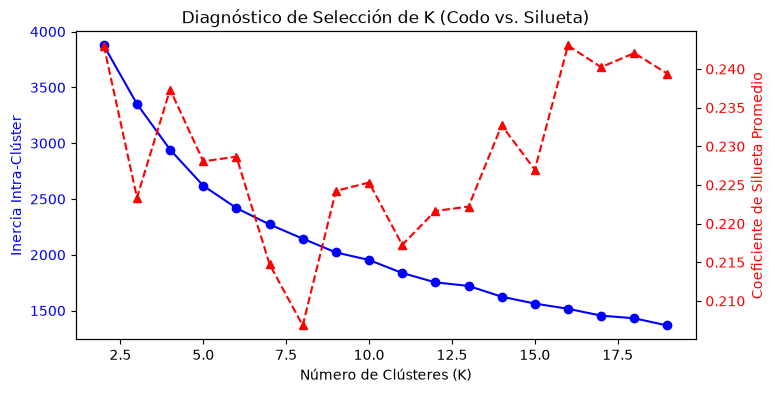

Silhouette Score (K=4):       0.2373
Davies-Bouldin Index (K=4):   1.5193 (Menor es mejor)
Calinski-Harabasz Score (K=4): 196.78 (Mayor es mejor)


In [59]:
# 1. Escalado obligatorio de las características
X_scaled = StandardScaler().fit_transform(X)

# 2. Evaluación del Método del Codo y Coeficiente de Silueta para un rango de K
inercias = []
siluetas = []
rango_k = range(2, 20)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X_scaled, labels))

# 3. Representación del Método del Codo y Silueta
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(rango_k, inercias, 'bo-', label="Inercia (WCSS)")
ax1.set_xlabel("Número de Clústeres (K)")
ax1.set_ylabel("Inercia Intra-Clúster", color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(rango_k, siluetas, 'r^--', label="Silhouette Score")
ax2.set_ylabel("Coeficiente de Silueta Promedio", color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title("Diagnóstico de Selección de K (Codo vs. Silueta)")
plt.show()

# 4. Cálculo de Índices Complementarios para K=n (ejemplo de mejor K)
best_kmeans = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
best_labels = best_kmeans.fit_predict(X_scaled)

db_index = davies_bouldin_score(X_scaled, best_labels)
ch_index = calinski_harabasz_score(X_scaled, best_labels)

print(f"Silhouette Score (K=4):       {silhouette_score(X_scaled, best_labels):.4f}")
print(f"Davies-Bouldin Index (K=4):   {db_index:.4f} (Menor es mejor)")
print(f"Calinski-Harabasz Score (K=4): {ch_index:.2f} (Mayor es mejor)")

# Si se dispone de etiquetas reales (y_true) para validación externa:
# print(f"Adjusted Rand Index (ARI):    {adjusted_rand_score(y_true, best_labels):.4f}")

#### Resumen de Métricas de Evaluación de Clustering

|Métrica|Tipo|Rango|Criterio de Optimización|Sensibilidad Geométrica|
|-------|----|-----|------------------------|-----------------------|
|Inercia (WCSS)|Interna|[0,+∞)|Minimizar (Buscar punto codo)|Penaliza desviaciones de formas esféricas|
|Silhouette Score|Interna|[−1.0,+1.0]|Maximizar (→+1.0)|Evalúa compacidad y separación relativa|
|Davies-Bouldin|Interna|[0,+∞)|Minimizar (→0)|Evalúa solapamiento de centroides|
|Calinski-Harabasz|Interna|[0,+∞)|Maximizar|Sensible a la varianza global|
|ARI (Adjusted Rand)|Externa|[−1.0,+1.0]|Maximizar (→+1.0)|Compara coincidencia estricta con ytrue|​

### Ideas Clave

- Complementariedad de Codo y Silueta: El Método del Codo proporciona una visión general del punto de inflexión del error, pero la Silueta aporta una métrica adimensional estandarizada entre $-1$ y $+1$ que facilita la comparación objetiva entre distintos modelos o valores de $K$.
- Silueta y algoritmos no esféricos: El coeficiente de silueta basado en la distancia euclídea global puede dar puntuaciones bajas a clústeres no convexos correctamente identificados por algoritmos como DBSCAN.
- Validación externa vs. interna: Las métricas internas ($s(i)$, DB, CH) sirven para seleccionar la configuración de hiperparámetros sin supervisión. Las métricas externas ($ARI$, $AMI$) se reservan para evaluar la alineación con conceptos o clasificaciones previas del negocio.
___